In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error, r2_score
import warnings

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

warnings.filterwarnings('ignore')
np.random.seed(42)  # For reproducibility

In [6]:
# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/BBCA.JK/history/")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

In [34]:
# -------------------------
# 1. Preprocessing Data
# -------------------------
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')
    cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for col in cols:
        df[col] = df[col].str.replace(',', '', regex=False).astype(float)
    df = df.sort_values('Date').reset_index(drop=True)
    return df

# -------------------------
# 1b. Tambahkan Indikator Teknikal (opsional)
# -------------------------
def add_technical_indicators(df):
    df = df.copy()
    df['MA_5'] = df['Close'].rolling(window=5).mean()
    df['MA_10'] = df['Close'].rolling(window=10).mean()
    df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
    df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = df['EMA_12'] - df['EMA_26']
    df['Momentum'] = df['Close'] - df['Close'].shift(1)
    df['Volatility_5'] = df['Close'].rolling(window=5).std()
    df['Price_Range'] = df['High'] - df['Low']
    # RSI
    delta = df['Close'].diff()
    gain = np.where(delta > 0, delta, 0)
    loss = np.where(delta < 0, -delta, 0)
    avg_gain = pd.Series(gain).rolling(window=14).mean()
    avg_loss = pd.Series(loss).rolling(window=14).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    df['RSI'] = 100 - (100 / (1 + rs))
    df.dropna(inplace=True)
    return df

# -------------------------
# 2. Outlier Removal (IQR)
# -------------------------
def remove_outliers_iqr(df, columns):
    df_out = df.copy()
    for column in columns:
        Q1 = df_out[column].quantile(0.25)
        Q3 = df_out[column].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_out = df_out[(df_out[column] >= lower) & (df_out[column] <= upper)]
    return df_out.reset_index(drop=True)

# -------------------------
# 3. ARIMA Rolling Forecast Function
# -------------------------
def forecast_arima(df, n_future=7, last_n_days=3, order=(7, 1, 0)):
    model = ARIMA(df['Close'], order=order)
    fit = model.fit()
    forecast = fit.forecast(steps=n_future)
    pred = forecast.values
    visualize_forecast(df, pred, n_future, last_n_days, model_label='ARIMA')
    if len(df) >= n_future:
        y_true = df['Close'].iloc[-n_future:].values
        mape = mean_absolute_percentage_error(y_true, pred)
        r2 = r2_score(y_true, pred)
        print(f"[ARIMA Rolling] MAPE: {mape:.2%}, R²: {r2:.3f}")
    return pred

# -------------------------
# 4. Prophet Rolling Forecast Function
# -------------------------
def forecast_prophet(df, n_future=7, last_n_days=3):
    try:
        from prophet import Prophet
    except ImportError:
        print("Prophet belum terinstal, skip baseline Prophet.")
        return None
    dfp = df[['Date', 'Close']].rename(columns={'Date': 'ds', 'Close': 'y'})
    model = Prophet(daily_seasonality=True, yearly_seasonality=True)
    model.fit(dfp)
    future = model.make_future_dataframe(periods=n_future)
    forecast = model.predict(future)
    pred = forecast[['ds', 'yhat']].set_index('ds')[-n_future:]['yhat'].values
    visualize_forecast(df, pred, n_future, last_n_days, model_label='Prophet')
    if len(df) >= n_future:
        y_true = df['Close'].iloc[-n_future:].values
        mape = mean_absolute_percentage_error(y_true, pred)
        r2 = r2_score(y_true, pred)
        print(f"[Prophet Rolling] MAPE: {mape:.2%}, R²: {r2:.3f}")
    return pred

# -------------------------
# 5. Plot Forecast
# -------------------------
def visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3, model_label='Forecast'):
    # Data aktual
    last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()
    last_date = df_clean['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    
    # Gabungkan titik akhir aktual + forecast agar garis forecast NYAMBUNG
    joined_dates = last_n_dates + future_dates
    forecast = np.array(forecast).flatten()
    joined_values = last_n_close + list(forecast)

    plt.figure(figsize=(13, 5))
    # Plot aktual
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', marker='o', color='C0', linewidth=2)
    # Plot forecast (nyambung dari akhir aktual)
    plt.plot(joined_dates, joined_values, label=f'Forecast {model_label} (Next {n_future} Days)',
             linestyle='--', marker='o', color='orange', linewidth=2)
    # Area forecast
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.10, label='Forecast Area')

    # Offset agar angka forecast dan aktual tidak saling tabrakan, menyesuaikan range grafik
    minv, maxv = min(joined_values), max(joined_values)
    offset = (maxv - minv) * 0.0125 if (maxv - minv) > 0 else 3  # fallback offset kalau range < 1

    # Label angka untuk aktual (letakkan di bawah titik)
    for date, value in zip(last_n_dates, last_n_close):
        plt.text(date, value - offset, f'{int(value)}', ha='center', va='top', fontsize=9, color='black', fontweight='bold')
    # Label angka untuk forecast (letakkan di atas titik)
    for date, value in zip(future_dates, forecast):
        plt.text(date, value + offset, f'{int(value)}', ha='center', va='bottom', fontsize=9, color='orange', fontweight='bold')

    # Set title dan axis
    plt.title(f'Close Price Forecasting: Last {last_n_days} Days + Next {n_future} Days ({model_label})')
    plt.xlabel('Date')
    plt.ylabel('Close Price')
    plt.legend()
    plt.xticks(ticks=joined_dates, rotation=45)
    plt.ylim(minv - offset*3, maxv + offset*3)
    plt.tight_layout()
    plt.show()



In [35]:
# 1. Preprocessing
df_clean = preprocess_data(df)
df_clean = add_technical_indicators(df_clean)
df_clean = remove_outliers_iqr(df_clean, ['Close', 'Open', 'High', 'Low', 'Volume'])

# 2. Setup fitur & target (bisa untuk statistik, EDA, dsb)
target_columns = ['Close']
feature_columns = ['Open', 'High', 'Low','MA_5', 'MA_10', 'EMA_12', 'EMA_26', 'MACD', 'Momentum', 'Volatility_5', 'Price_Range', 'RSI']


== Baseline ARIMA ==


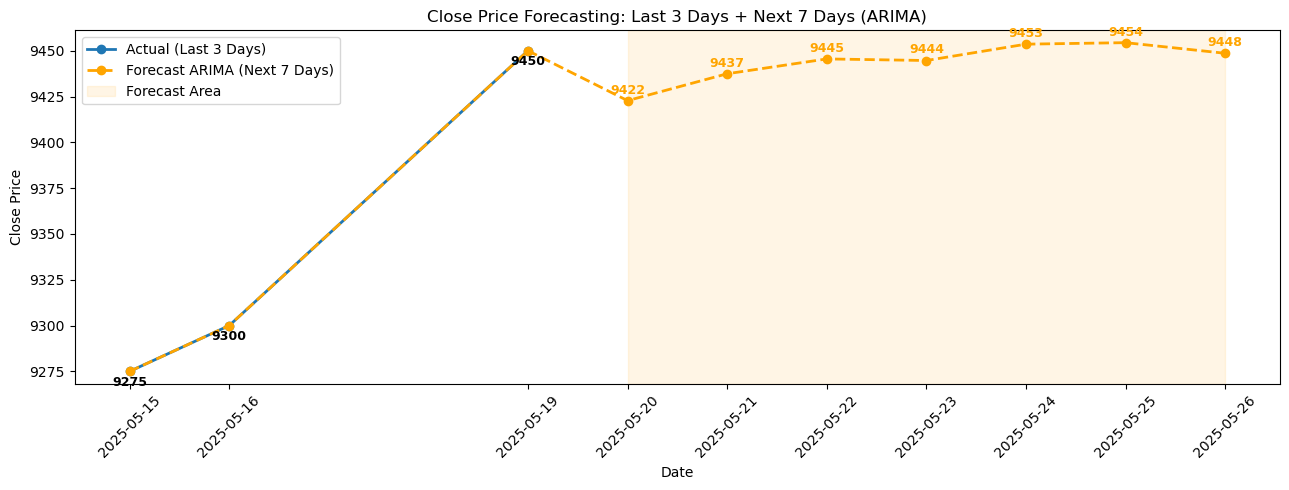

[ARIMA Rolling] MAPE: 2.77%, R²: -2.258


In [36]:
# 3. Forecast ARIMA
print('\n== Baseline ARIMA ==')
forecast_arima_vals = forecast_arima(df_clean, n_future=7, last_n_days=3)


== Baseline Prophet ==


15:11:56 - cmdstanpy - INFO - Chain [1] start processing
15:11:56 - cmdstanpy - INFO - Chain [1] done processing


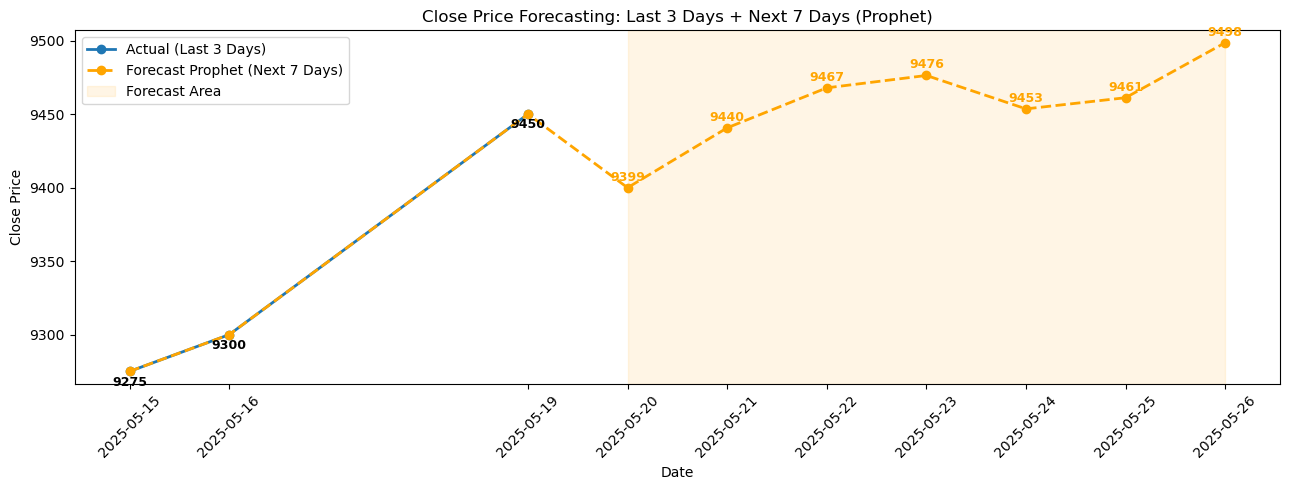

[Prophet Rolling] MAPE: 2.90%, R²: -2.386


In [37]:
# 4. Forecast Prophet
print('\n== Baseline Prophet ==')
forecast_prophet_vals = forecast_prophet(df_clean, n_future=7, last_n_days=3)

In [38]:
# # 5. Compare Plot ARIMA & Prophet
# compare_forecast_plot(df_clean, forecast_arima_vals, forecast_prophet_vals, n_future=7, last_n_days=3)